# Bài 6 (Trang 26) – Giảm số màu ảnh bằng k-Means

**Họ tên:** Mai Quốc Đại — **MSSV:** 6451071013 — **Lớp:** CQ.64.CNTT

## Khai báo thư viện

In [1]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
import os
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
print("Đã import thư viện")

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Đã import thư viện


## Đọc ảnh và hiển thị

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


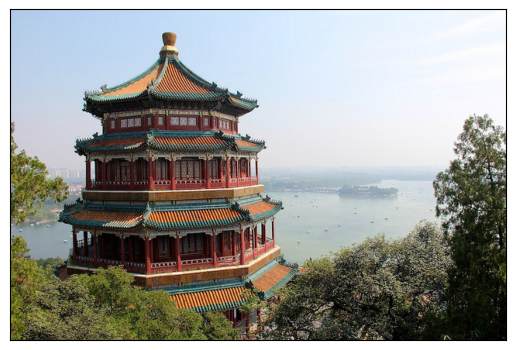

In [2]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
image = Image.open("data/image.png").convert("RGB")
axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)
plt.show()

## Chuyển ảnh thành mảng số, lấy chiều cao/rộng

In [3]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]
print("Kích thước ảnh:", imarr.shape)
print("Số màu khác nhau trong ảnh gốc:", len(np.unique(imarr.reshape(-1, 3), axis=0)))

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
Kích thước ảnh: (427, 640, 3)


Số màu khác nhau trong ảnh gốc: 96615


## Đưa giá trị màu về [0,1] và chuyển mảng 3 chiều thành 2 chiều

In [4]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
data = imarr / 255.0
data = data.reshape(rows * cols, 3)
print(data.shape)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
(273280, 3)


## Gom cụm với 32 màu và lấy mảng ảnh mới

In [5]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
kmeans = KMeans(n_clusters=32, max_iter=300, n_init=1, random_state=42)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]
print("Bảng màu mới:", kmeans.cluster_centers_.shape)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Bảng màu mới: (32, 3)


## Khôi phục mảng 3 chiều và so sánh với ảnh gốc

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


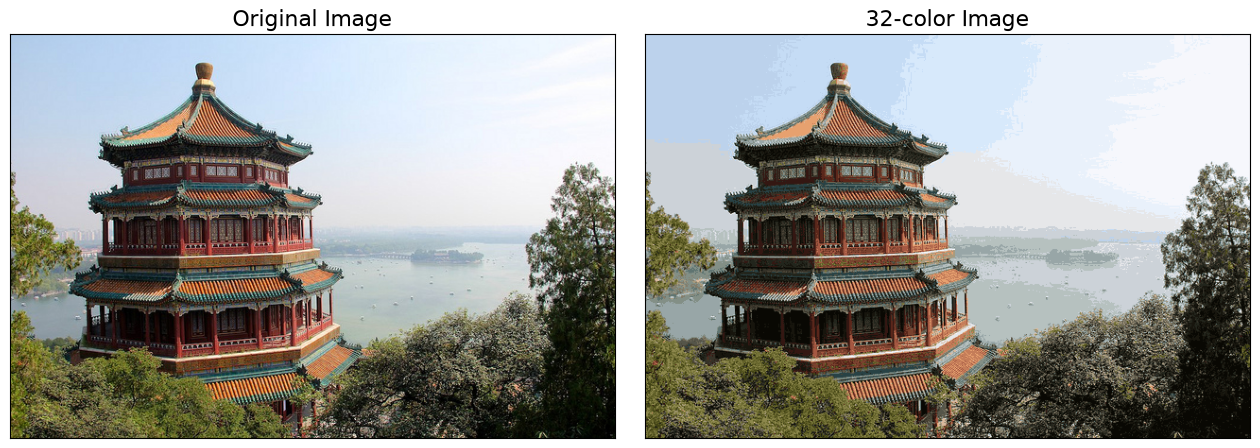

In [6]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
img_recolored = new_colors.reshape(imarr.shape)
fig, ax = plt.subplots(1, 2, figsize=(16, 6), subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title("Original Image", size=16)
ax[1].imshow(img_recolored)
ax[1].set_title("32-color Image", size=16)
plt.show()

## Lưu ảnh kết quả và so sánh kích thước file

In [7]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
os.makedirs("output", exist_ok=True)
img_out = img_recolored * 255
new_img = Image.fromarray(img_out.astype(np.uint8))
new_img.save("output/compressed_img2.png", optimize=True)
# ảnh 32 màu có thể lưu dạng bảng màu (palette) 5 bit/pixel -> nhỏ hơn nhiều
new_img.quantize(colors=32, method=Image.Quantize.FASTOCTREE).save("output/compressed_img2_palette.png", optimize=True)
image.save("output/original.png", optimize=True)
for f in ["output/original.png", "output/compressed_img2.png", "output/compressed_img2_palette.png"]:
    print(f"{f:40s}: {os.path.getsize(f) / 1024:8.1f} KB")

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT
output/original.png                     :    469.9 KB
output/compressed_img2.png              :    263.4 KB
output/compressed_img2_palette.png      :     75.0 KB


## Thử với các số màu khác nhau

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


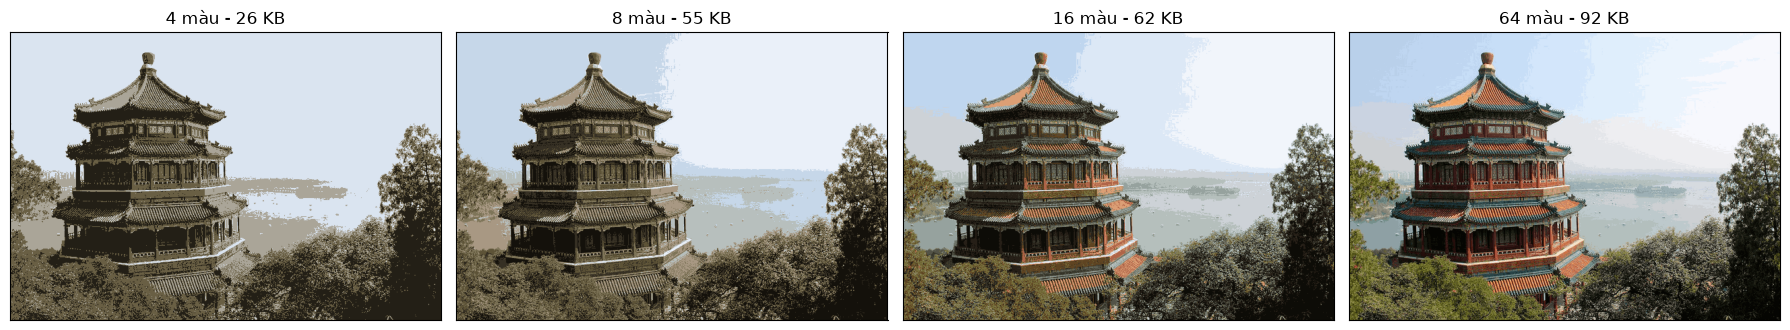

In [8]:
print("Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT")
fig, ax = plt.subplots(1, 4, figsize=(18, 4), subplot_kw=dict(xticks=[], yticks=[]))
for axi, k in zip(ax, [4, 8, 16, 64]):
    km = KMeans(n_clusters=k, n_init=1, random_state=42).fit(data)
    out = (km.cluster_centers_[km.labels_].reshape(imarr.shape) * 255).astype(np.uint8)
    path = f"output/compressed_{k}_colors.png"
    Image.fromarray(out).quantize(colors=k, method=Image.Quantize.FASTOCTREE).save(path, optimize=True)
    axi.imshow(out); axi.set_title(f"{k} màu - {os.path.getsize(path) / 1024:.0f} KB")
plt.tight_layout(); plt.show()

**Nhận xét:**

- Ảnh gốc có 96 615 màu khác nhau. Sau khi gom cụm về 32 màu, ảnh gần như không khác biệt khi nhìn bằng mắt thường, chỉ các vùng chuyển màu mịn (bầu trời) xuất hiện vài dải màu.
- Lưu dạng RGB thông thường, file giảm từ ~470 KB xuống ~263 KB. Khi lưu dưới dạng ảnh bảng màu (palette, chỉ cần 5 bit cho mỗi pixel vì có 32 màu), file chỉ còn ~75 KB, khoảng 16% kích thước ban đầu.
- Số màu k càng nhỏ thì file càng nhẹ nhưng ảnh càng mất chi tiết (4 – 8 màu thấy rõ các mảng màu). Có thể chọn k để cân bằng giữa chất lượng ảnh và kích thước file mong muốn.